# Diagnóstico dos dados SONDA-MD (meteorologia, 10 min)

Este notebook lê os arquivos anuais `sonda_MD_AAAA.csv` (pasta `2026/sonda_unificada/MD`, gerados por
`executar/juntar_sonda_por_ano.py`) e mostra **onde faltam dados** e **onde há valores estranhos** em
toda a série e em todas as variáveis.

**Nada é corrigido aqui**, o notebook só mostra. Lembre que os CSV já têm três alterações em relação
aos `.dat`: começam em 01/12/2023, têm a umidade acima de 100 % convertida para 100 % e têm as falhas
do barômetro (quedas para ~602 mb) trocadas por interpolação linear, marcadas na coluna
`press_interpolada`. Por isso a pressão quase não aparece mais como valor estranho.

Roteiro:
1. Configuração e leitura
2. Registros ausentes (horários que não existem nos arquivos)
3. Valores faltantes por variável, com o intervalo exato de cada falha
4. Valores estranhos: as regras e os episódios encontrados
5. Mapas da série inteira
6. Séries completas e zoom nos episódios
7. Exportação das tabelas

**Horário:** os dados estão em **UTC**; cada `TIMESTAMP` marca o **fim** do intervalo de 10 min.
As tabelas mostram o início em UTC e também em hora local (UTC−3); os mapas usam hora local.

## 1. Configuração e leitura

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "config").is_dir())
sys.path.insert(0, str(RAIZ))

from config.caminhos_e_parametros import PASTA_SONDA_UNIFICADA

PASTA_MD = PASTA_SONDA_UNIFICADA / "MD"
INICIO = None  # ex.: pd.Timestamp("2025-01-01 00:00:00") para olhar so um trecho
FIM = None     # ex.: pd.Timestamp("2025-12-31 23:50:00")
PASSO = pd.Timedelta(minutes=10)
FUSO_LOCAL = pd.Timedelta(hours=-3)
COLUNAS_CONTROLE = ["TIMESTAMP", "RECORD", "Id", "Year", "Jday", "Min"]
SALVAR_TABELAS = True
PASTA_SAIDA = PASTA_MD / "diagnostico"

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Pasta dos CSV:", PASTA_MD)

Pasta dos CSV: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\2026\sonda_unificada\MD


In [4]:
arquivos = sorted(PASTA_MD.glob("sonda_MD_*.csv"))
bruto = pd.concat(
    [pd.read_csv(arquivo, parse_dates=["TIMESTAMP"]).assign(arquivo_origem=arquivo.name) for arquivo in arquivos],
    ignore_index=True,
)
if INICIO is not None:
    bruto = bruto[bruto["TIMESTAMP"] >= INICIO]
if FIM is not None:
    bruto = bruto[bruto["TIMESTAMP"] <= FIM]

repetidos = bruto["TIMESTAMP"].duplicated()
bruto = bruto[~repetidos].sort_values("TIMESTAMP")

# Unidades e processamento: aba "variaveis" do .xlsx gerado junto com cada CSV
dicionario = pd.read_excel(arquivos[0].with_suffix(".xlsx"), sheet_name="variaveis")
# press_interpolada e uma marcacao (True/False), nao uma medida
dicionario = dicionario[~dicionario["variavel"].isin(COLUNAS_CONTROLE)
                        & ~dicionario["variavel"].str.endswith("_interpolada")].reset_index(drop=True)
VARIAVEIS = list(dicionario["variavel"])
UNIDADES = dict(zip(dicionario["variavel"], dicionario["unidade"]))

# Grade regular de 10 min: horarios que nao existem nos arquivos viram linhas vazias
grade = pd.date_range(bruto["TIMESTAMP"].min(), bruto["TIMESTAMP"].max(), freq=PASSO, name="TIMESTAMP")
dados = bruto.set_index("TIMESTAMP").reindex(grade)
registro_ausente = dados["arquivo_origem"].isna()

print("Arquivos lidos:", ", ".join(a.name for a in arquivos))
print(f"Periodo: {grade[0]:%d/%m/%Y %H:%M} a {grade[-1]:%d/%m/%Y %H:%M} UTC")
print(f"Registros esperados (a cada 10 min): {len(grade):,}".replace(",", "."))
print(f"Registros presentes: {(~registro_ausente).sum():,}".replace(",", "."))
print(f"Registros ausentes: {registro_ausente.sum()}")
print(f"Horarios repetidos entre os arquivos: {repetidos.sum()}")
display(dicionario)

Arquivos lidos: sonda_MD_2023.csv, sonda_MD_2024.csv, sonda_MD_2025.csv, sonda_MD_2026.csv
Periodo: 01/12/2023 00:00 a 30/06/2026 23:50 UTC
Registros esperados (a cada 10 min): 135.792
Registros presentes: 135.790
Registros ausentes: 2
Horarios repetidos entre os arquivos: 0


,variavel,unidade,processamento
0,tp_sfc,°C,Avg
1,humid,%,Avg
2,press,mb,Avg
3,rain,mm,Tot
4,ws10_avg,m/s,WVc
5,wd10_avg,Deg,WVc
6,wd10_std,Deg,WVc
7,ws10_std,m/s,Std
8,ws10_min,m/s,Min
9,ws10_max,m/s,Max


Funções auxiliares: `intervalos` agrupa registros consecutivos marcados (faltando ou estranhos) em
episódios, com início, fim e duração exatos.

In [5]:
def formatar_duracao(duracao):
    minutos = int(duracao.total_seconds() // 60)
    dias, minutos = divmod(minutos, 1440)
    horas, minutos = divmod(minutos, 60)
    partes = [f"{dias} d" if dias else "", f"{horas} h" if horas else "", f"{minutos} min" if minutos else ""]
    return " ".join(p for p in partes if p)


def intervalos(mascara):
    mascara = mascara.fillna(False).astype(bool)
    colunas = ["inicio_utc", "fim_utc", "registros", "duracao", "inicio_hora_local"]
    if not mascara.any():
        return pd.DataFrame(columns=colunas)
    grupo = (mascara != mascara.shift()).cumsum()[mascara]
    horarios = pd.Series(mascara.index[mascara], index=mascara.index[mascara])
    tabela = horarios.groupby(grupo.values).agg(["min", "max", "size"]).reset_index(drop=True)
    tabela.columns = ["inicio_utc", "fim_utc", "registros"]
    tabela["duracao"] = (tabela["registros"] * PASSO).map(formatar_duracao)
    tabela["inicio_hora_local"] = (tabela["inicio_utc"] + FUSO_LOCAL).dt.strftime("%d/%m/%Y %H:%M")
    return tabela[colunas]

## 2. Registros ausentes

Horários em que **nenhum** arquivo tem registro: a linha inteira está faltando, em todas as variáveis.

In [6]:
tabela_ausentes = intervalos(registro_ausente)
print(f"{len(tabela_ausentes)} intervalos com registros ausentes")
display(tabela_ausentes)

2 intervalos com registros ausentes


,inicio_utc,fim_utc,registros,duracao,inicio_hora_local
0,2025-06-24 17:40:00,2025-06-24 17:40:00,1,10 min,24/06/2025 14:40
1,2025-07-02 20:50:00,2025-07-02 20:50:00,1,10 min,02/07/2025 17:50


## 3. Valores faltantes por variável

Um valor falta quando o registro não existe (seção 2) ou quando a célula do CSV está vazia (era `NAN`
no `.dat` original).
A tabela-resumo mostra, para cada variável, quanto falta e qual a maior falha; a tabela seguinte lista
**cada intervalo**, com início e fim exatos.

In [7]:
faltante = dados[VARIAVEIS].isna()

linhas_resumo, tabelas_falhas = [], []
for variavel in VARIAVEIS:
    tabela = intervalos(faltante[variavel])
    tabela.insert(0, "variavel", variavel)
    tabela["tipo"] = [
        "registro ausente" if registro_ausente.loc[ini:fim].all() else "valor vazio (NAN)"
        for ini, fim in zip(tabela["inicio_utc"], tabela["fim_utc"])
    ]
    tabelas_falhas.append(tabela)
    maior = tabela.loc[tabela["registros"].idxmax()] if len(tabela) else None
    linhas_resumo.append({
        "variavel": variavel,
        "unidade": UNIDADES[variavel],
        "faltando": int(faltante[variavel].sum()),
        "faltando_%": round(100 * faltante[variavel].mean(), 3),
        "falhas": len(tabela),
        "maior_falha": maior["duracao"] if maior is not None else "",
        "maior_falha_inicio_utc": maior["inicio_utc"] if maior is not None else pd.NaT,
    })

resumo_faltantes = pd.DataFrame(linhas_resumo)
falhas = pd.concat(tabelas_falhas, ignore_index=True)
display(resumo_faltantes)

,variavel,unidade,faltando,faltando_%,falhas,maior_falha,maior_falha_inicio_utc
0,tp_sfc,°C,2,0.001,2,10 min,2025-06-24 17:40:00
1,humid,%,1282,0.944,58,15 h 10 min,2025-04-24 22:30:00
2,press,mb,3,0.002,3,10 min,2025-06-24 17:40:00
3,rain,mm,2,0.001,2,10 min,2025-06-24 17:40:00
4,ws10_avg,m/s,24,0.018,6,2 h 50 min,2024-01-11 01:20:00
5,wd10_avg,Deg,24,0.018,6,2 h 50 min,2024-01-11 01:20:00
6,wd10_std,Deg,24,0.018,6,2 h 50 min,2024-01-11 01:20:00
7,ws10_std,m/s,2,0.001,2,10 min,2025-06-24 17:40:00
8,ws10_min,m/s,2,0.001,2,10 min,2025-06-24 17:40:00
9,ws10_max,m/s,2,0.001,2,10 min,2025-06-24 17:40:00


Todos os intervalos de falta, da maior para a menor duração. Para ver uma variável só, troque o nome
em `VER_VARIAVEL` (ou use `None` para todas).

In [8]:
VER_VARIAVEL = None  # ex.: "humid"

tabela = falhas if VER_VARIAVEL is None else falhas.query("variavel == @VER_VARIAVEL")
display(tabela.sort_values("registros", ascending=False).reset_index(drop=True))

,variavel,inicio_utc,fim_utc,registros,duracao,inicio_hora_local,tipo
0,humid,2025-04-24 22:30:00,2025-04-25 13:30:00,91,15 h 10 min,24/04/2025 19:30,valor vazio (NAN)
1,humid,2025-03-31 22:40:00,2025-04-01 12:20:00,83,13 h 50 min,31/03/2025 19:40,valor vazio (NAN)
2,humid,2025-04-19 23:40:00,2025-04-20 11:40:00,73,12 h 10 min,19/04/2025 20:40,valor vazio (NAN)
3,humid,2025-04-17 01:20:00,2025-04-17 12:30:00,68,11 h 20 min,16/04/2025 22:20,valor vazio (NAN)
4,humid,2025-04-04 21:10:00,2025-04-05 08:00:00,66,11 h,04/04/2025 18:10,valor vazio (NAN)
5,humid,2025-04-10 01:50:00,2025-04-10 12:00:00,62,10 h 20 min,09/04/2025 22:50,valor vazio (NAN)
6,humid,2025-04-11 02:10:00,2025-04-11 10:50:00,53,8 h 50 min,10/04/2025 23:10,valor vazio (NAN)
7,humid,2025-04-02 01:30:00,2025-04-02 10:10:00,53,8 h 50 min,01/04/2025 22:30,valor vazio (NAN)
8,humid,2025-03-29 02:30:00,2025-03-29 11:10:00,53,8 h 50 min,28/03/2025 23:30,valor vazio (NAN)
9,humid,2025-04-25 21:10:00,2025-04-26 05:50:00,53,8 h 50 min,25/04/2025 18:10,valor vazio (NAN)


## 4. Valores estranhos

Cada valor é testado pelas regras abaixo, na ordem; vale a primeira que ele violar. As regras só
**marcam** os valores, não alteram nada. Os limites ficam na célula seguinte e podem ser ajustados.

| Regra | O que marca | Por quê |
|---|---|---|
| `codigo_falha` | valores iguais ou acima de 999 em módulo (ex.: 999, 999,99) | códigos que o datalogger grava quando o sensor falha |
| `impossivel` | umidade acima de 100 % ou abaixo de 0; chuva ou velocidade do vento negativas; direção fora de 0–360° | valores que não existem fisicamente |
| `umidade_100` | umidade exatamente igual a 100 % | nos CSV, os valores acima de 100 % foram convertidos para 100 %; esta regra mostra onde isso aconteceu (nos `.dat` originais, só um valor era exatamente 100) |
| `vento_com_falha` | demais colunas de vento num registro que tem código de falha no vento | o desvio padrão e as médias desse registro foram calculados com leituras ruins |
| `constante_no_dia` | variável que fica exatamente com o mesmo valor o dia inteiro | sensor travado ou desligado (ex.: direção do vento = 0 em 2023) |
| `desvio_da_mediana` | pressão que se afasta muito da mediana das 6 h ao redor | pega o episódio inteiro de queda (ex.: os ~602 mb), não só a borda |
| `salto_brusco` | variação maior que o limite entre dois registros seguidos (10 min), **e** valor longe da mediana das 6 h ao redor | mudanças rápidas demais; o segundo critério evita marcar o registro que só "volta ao normal" depois de uma falha |

**Atenção ao `salto_brusco` na temperatura e na umidade:** vários saltos acontecem juntos (a temperatura
cai 6–8 °C e a umidade sobe 20–30 pontos em 10 min, por exemplo em 16/10/2024 e 05/02/2025). Esse é o
comportamento de uma frente de rajada de tempestade, um fenômeno **real**. Por isso a regra só marca
para **verificar**, não indica erro.

In [9]:
LIMITE_CODIGO = 999
FAIXA_POSSIVEL = {
    "humid": (0, 100),
    "rain": (0, None),
    "ws10_avg": (0, None), "ws10_std": (0, None), "ws10_min": (0, None), "ws10_max": (0, None),
    "wd10_avg": (0, 360), "wd10_std": (0, None), "wd10_min": (0, 360), "wd10_max": (0, 360),
}
COLUNAS_VENTO = ["ws10_avg", "wd10_avg", "wd10_std", "ws10_std", "ws10_min", "ws10_max", "wd10_min", "wd10_max"]
CONSTANTE_VERIFICAR = ["tp_sfc", "humid", "press", "ws10_avg", "wd10_avg", "wd10_std"]
JANELA_MEDIANA = "6h"
LIMITE_DESVIO_MEDIANA = {"press": 5.0}                     # mb
LIMITE_SALTO = {"tp_sfc": 5.0, "humid": 25.0, "press": 2.0}  # por 10 min

Antes de aplicar o `salto_brusco`, veja como as variações reais se distribuem. Cada histograma mostra
a variação entre registros seguidos (eixo y em escala log); a linha vermelha é o limite escolhido.
Na pressão, as variações reais ficam abaixo de ~1 mb, e as falhas aparecem separadas, à direita.

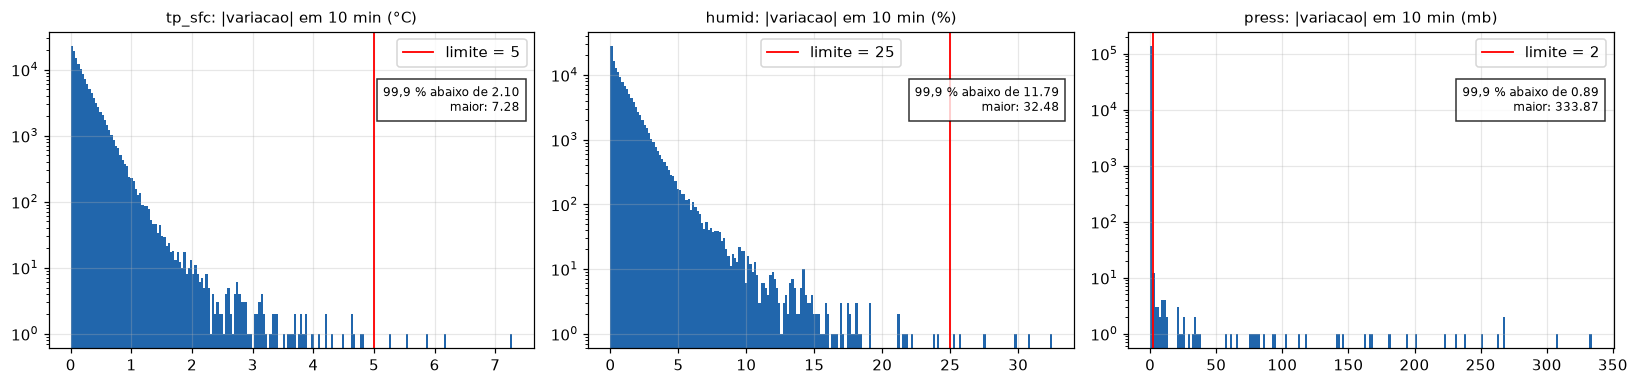

In [10]:
fig, eixos = plt.subplots(1, len(LIMITE_SALTO), figsize=(15, 3.6))
for eixo, (variavel, limite) in zip(eixos, LIMITE_SALTO.items()):
    serie = dados[variavel].where(dados[variavel].abs() < LIMITE_CODIGO)
    variacao = serie.diff().abs().dropna()
    eixo.hist(variacao, bins=200, color="#2166ac", log=True)
    eixo.axvline(limite, color="red", lw=1.2, label=f"limite = {limite:g}")
    eixo.set_title(f"{variavel}: |variacao| em 10 min ({UNIDADES[variavel]})", fontsize=10)
    eixo.legend()
    q999 = variacao.quantile(0.999)
    eixo.text(0.97, 0.75, f"99,9 % abaixo de {q999:.2f}\nmaior: {variacao.max():.2f}",
              transform=eixo.transAxes, ha="right", fontsize=8, bbox={"facecolor": "white", "alpha": 0.8})
fig.tight_layout()
plt.show()

In [11]:
medidas = dados[VARIAVEIS]
regras = {}

regras["codigo_falha"] = medidas.abs() >= LIMITE_CODIGO

impossivel = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
for variavel, (minimo, maximo) in FAIXA_POSSIVEL.items():
    if minimo is not None:
        impossivel[variavel] |= medidas[variavel] < minimo
    if maximo is not None:
        impossivel[variavel] |= medidas[variavel] > maximo
regras["impossivel"] = impossivel

umidade_100 = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
umidade_100["humid"] = medidas["humid"] == 100
regras["umidade_100"] = umidade_100

com_codigo_vento = regras["codigo_falha"][COLUNAS_VENTO].any(axis=1)
vento_com_falha = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
for variavel in COLUNAS_VENTO:
    vento_com_falha[variavel] = com_codigo_vento & medidas[variavel].notna()
regras["vento_com_falha"] = vento_com_falha

constante = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
for variavel in CONSTANTE_VERIFICAR:
    por_dia = medidas[variavel].groupby(medidas.index.normalize())
    dia_travado = (por_dia.transform("std") == 0) & (por_dia.transform("count") >= 72)
    constante[variavel] = dia_travado & medidas[variavel].notna()
regras["constante_no_dia"] = constante

desvio = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
for variavel, limite in LIMITE_DESVIO_MEDIANA.items():
    serie = medidas[variavel].where(~regras["codigo_falha"][variavel])
    mediana = serie.rolling(JANELA_MEDIANA, center=True, min_periods=6).median()
    desvio[variavel] = (serie - mediana).abs() > limite
regras["desvio_da_mediana"] = desvio

salto = pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)
for variavel, limite in LIMITE_SALTO.items():
    serie = medidas[variavel].where(~regras["codigo_falha"][variavel])
    mediana = serie.rolling(JANELA_MEDIANA, center=True, min_periods=6).median()
    salto[variavel] = (serie.diff().abs() > limite) & ((serie - mediana).abs() > limite)
regras["salto_brusco"] = salto

# Cada valor recebe a primeira regra que violar
regra_do_valor = pd.DataFrame("", index=medidas.index, columns=VARIAVEIS)
for nome, mascara in regras.items():
    regra_do_valor = regra_do_valor.mask((regra_do_valor == "") & mascara.fillna(False), nome)
estranho = regra_do_valor != ""

contagem = pd.DataFrame({nome: (regra_do_valor == nome).sum() for nome in regras})
contagem["total"] = contagem.sum(axis=1)
display(contagem[contagem["total"] > 0])

,codigo_falha,impossivel,umidade_100,vento_com_falha,constante_no_dia,desvio_da_mediana,salto_brusco,total
humid,0,0,3364,0,0,0,1,3365
press,0,0,0,0,0,63,5,68
ws10_avg,0,0,0,21,0,0,0,21
wd10_avg,0,0,0,21,0,0,0,21
wd10_std,0,0,0,21,0,0,0,21
ws10_std,0,0,0,43,0,0,0,43
ws10_min,22,0,0,21,0,0,0,43
ws10_max,43,0,0,0,0,0,0,43
wd10_min,22,0,0,21,0,0,0,43
wd10_max,43,0,0,0,0,0,0,43


Episódios de valores estranhos: registros seguidos com a mesma regra viram um episódio, com início, fim,
duração e os valores mínimo e máximo encontrados.

In [12]:
tabelas_estranhos = []
for variavel in VARIAVEIS:
    for nome in regras:
        mascara = regra_do_valor[variavel] == nome
        if not mascara.any():
            continue
        tabela = intervalos(mascara)
        valores = [medidas.loc[ini:fim, variavel] for ini, fim in zip(tabela["inicio_utc"], tabela["fim_utc"])]
        tabela.insert(0, "regra", nome)
        tabela.insert(0, "variavel", variavel)
        tabela["valor_min"] = [v.min() for v in valores]
        tabela["valor_max"] = [v.max() for v in valores]
        tabelas_estranhos.append(tabela)

episodios_estranhos = pd.concat(tabelas_estranhos, ignore_index=True) if tabelas_estranhos else pd.DataFrame()
print(f"{len(episodios_estranhos)} episodios de valores estranhos")
display(episodios_estranhos.sort_values(["variavel", "inicio_utc"]).reset_index(drop=True))

450 episodios de valores estranhos


,variavel,regra,inicio_utc,fim_utc,registros,duracao,inicio_hora_local,valor_min,valor_max
0,humid,umidade_100,2025-03-26 04:20:00,2025-03-26 04:30:00,2,20 min,26/03/2025 01:20,100.0000,100.0000
1,humid,umidade_100,2025-03-26 05:30:00,2025-03-26 05:40:00,2,20 min,26/03/2025 02:30,100.0000,100.0000
2,humid,umidade_100,2025-03-26 10:30:00,2025-03-26 10:30:00,1,10 min,26/03/2025 07:30,100.0000,100.0000
3,humid,umidade_100,2025-03-26 22:20:00,2025-03-26 22:40:00,3,30 min,26/03/2025 19:20,100.0000,100.0000
4,humid,umidade_100,2025-03-27 00:00:00,2025-03-27 00:30:00,4,40 min,26/03/2025 21:00,100.0000,100.0000
...,...,...,...,...,...,...,...,...,...
445,ws10_std,vento_com_falha,2026-01-24 21:00:00,2026-01-24 21:50:00,6,1 h,24/01/2026 18:00,0.0000,473.9324
446,ws10_std,vento_com_falha,2026-03-11 03:50:00,2026-03-11 04:00:00,2,20 min,11/03/2026 00:50,422.6738,471.0902
447,ws10_std,vento_com_falha,2026-03-20 19:30:00,2026-03-20 19:40:00,2,20 min,20/03/2026 16:30,174.9240,283.2849
448,ws10_std,vento_com_falha,2026-03-20 20:00:00,2026-03-20 20:20:00,3,30 min,20/03/2026 17:00,0.0000,478.0757


## 5. Mapas da série inteira

### 5.1 Visão geral: todas as variáveis, dia a dia

Cada coluna é um dia e cada linha, uma variável. Em cima: percentual de valores faltando no dia.
Embaixo: quantidade de valores estranhos no dia. Branco = nenhum problema.

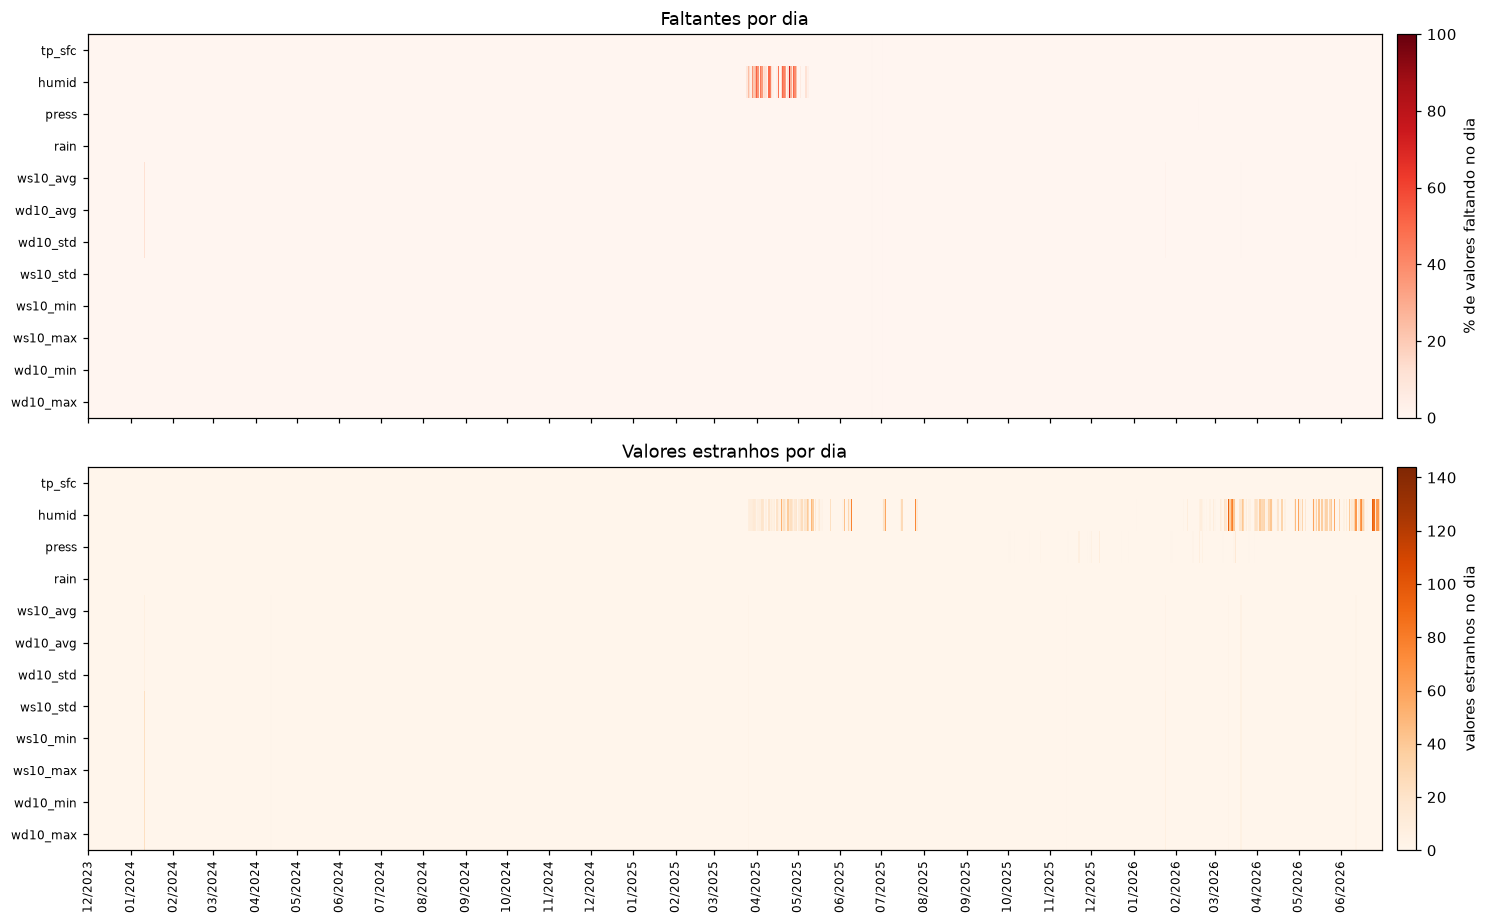

In [13]:
falta_dia = faltante.groupby(faltante.index.normalize()).mean() * 100
estranho_dia = estranho.groupby(estranho.index.normalize()).sum()

fig, (eixo_a, eixo_b) = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)
for eixo, tabela, cmap, rotulo in [
    (eixo_a, falta_dia, "Reds", "% de valores faltando no dia"),
    (eixo_b, estranho_dia.clip(upper=144), "Oranges", "valores estranhos no dia"),
]:
    imagem = eixo.imshow(tabela.T.to_numpy(), aspect="auto", interpolation="nearest", cmap=cmap,
                         vmin=0, vmax=100 if tabela is falta_dia else 144)
    eixo.set_yticks(range(len(VARIAVEIS)), VARIAVEIS, fontsize=8)
    eixo.grid(False)
    fig.colorbar(imagem, ax=eixo, label=rotulo, pad=0.01)
dias = falta_dia.index
meses = [i for i, dia in enumerate(dias) if dia.day == 1]
eixo_b.set_xticks(meses, [dias[i].strftime("%m/%Y") for i in meses], rotation=90, fontsize=8)
eixo_a.set_title("Faltantes por dia")
eixo_b.set_title("Valores estranhos por dia")
fig.tight_layout()
plt.show()

### 5.2 Mapa detalhado de cada variável

Cada coluna é um dia; cada linha, um horário do dia (**hora local**, de 10 em 10 min). Cada quadradinho
é um registro:

- **cinza claro**: valor válido;
- **vermelho**: valor vazio (`NAN` no arquivo);
- **preto**: registro ausente (a linha inteira não existe);
- **laranja**: valor estranho (seção 4).

Assim dá para ver quando cada falha acontece e em que horário. Por exemplo, as falhas noturnas da
umidade em mar–mai/2025. Edite `VARIAVEIS_MAPA` para escolher as variáveis.

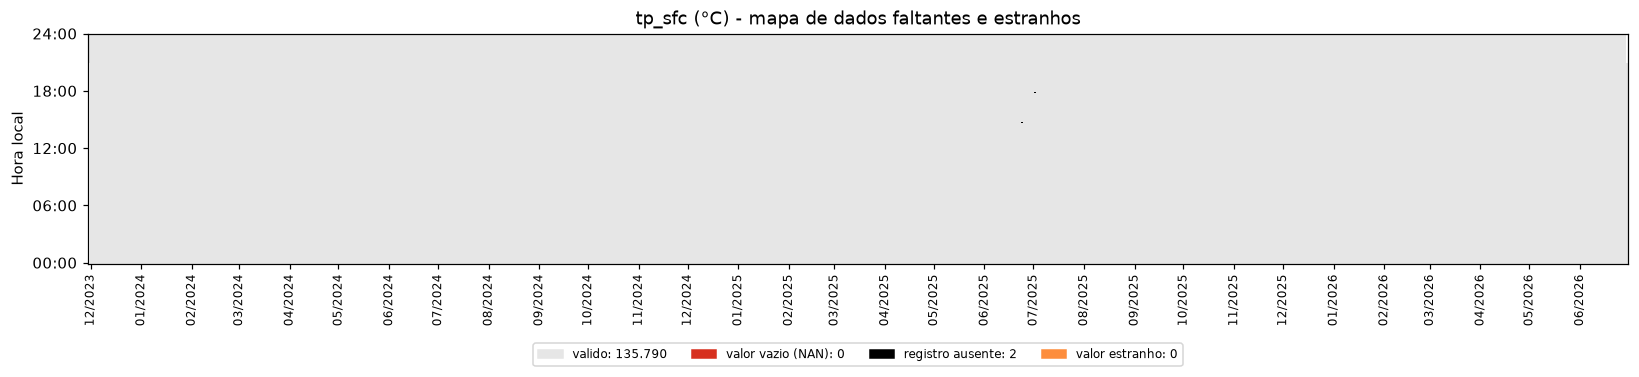

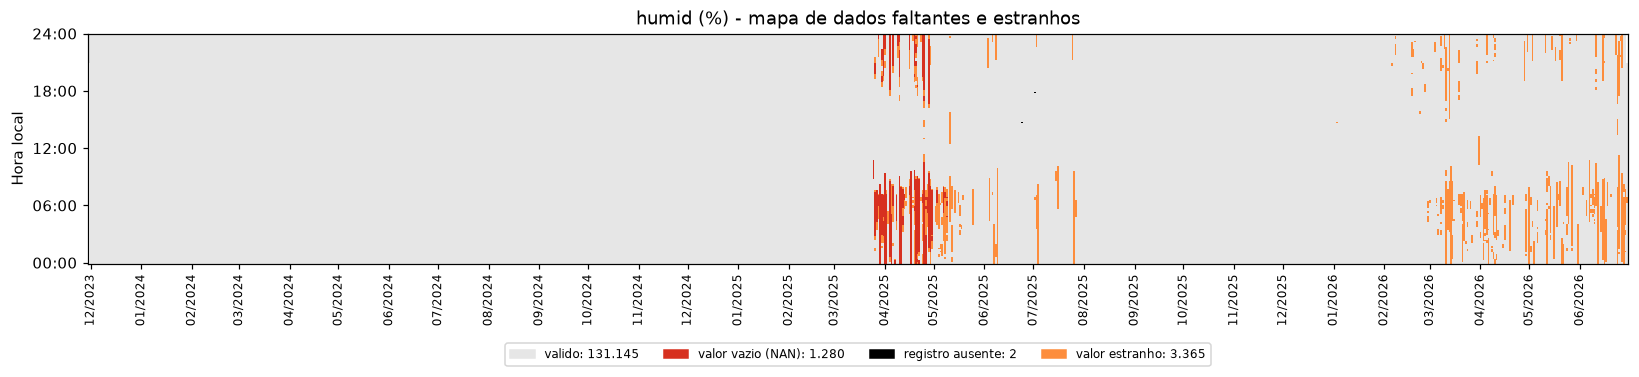

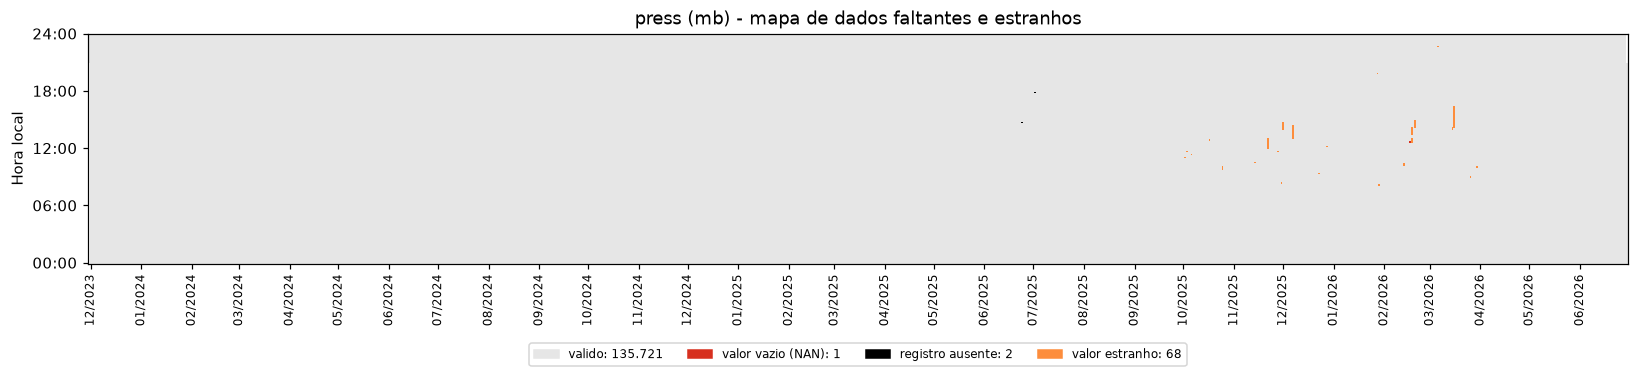

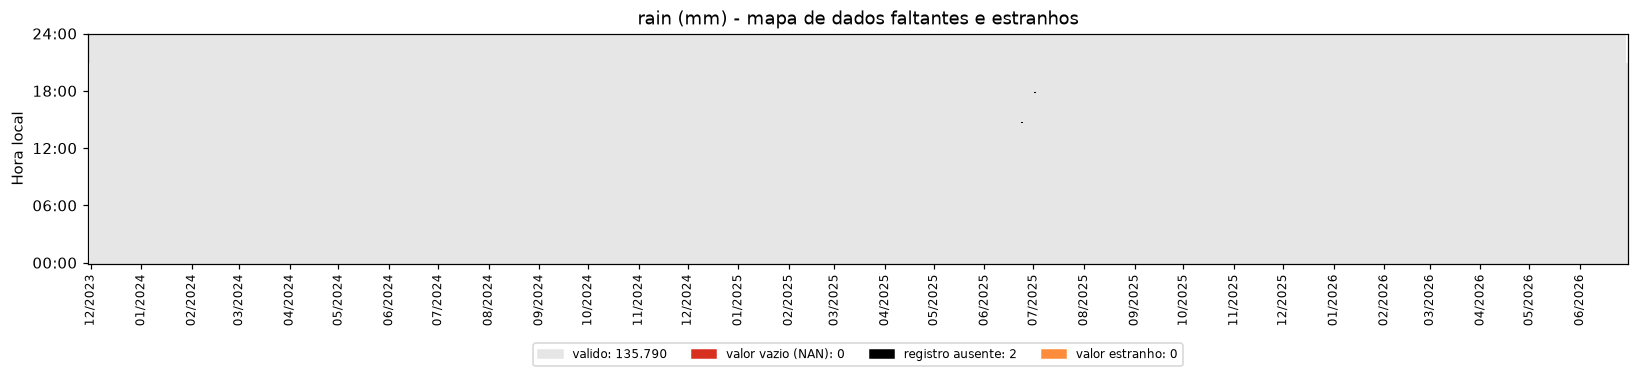

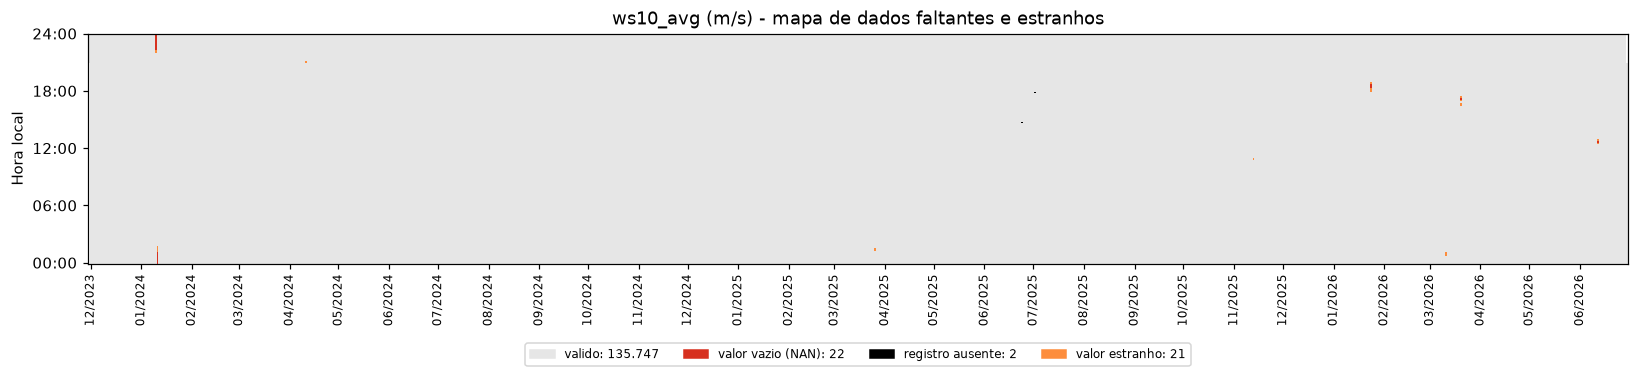

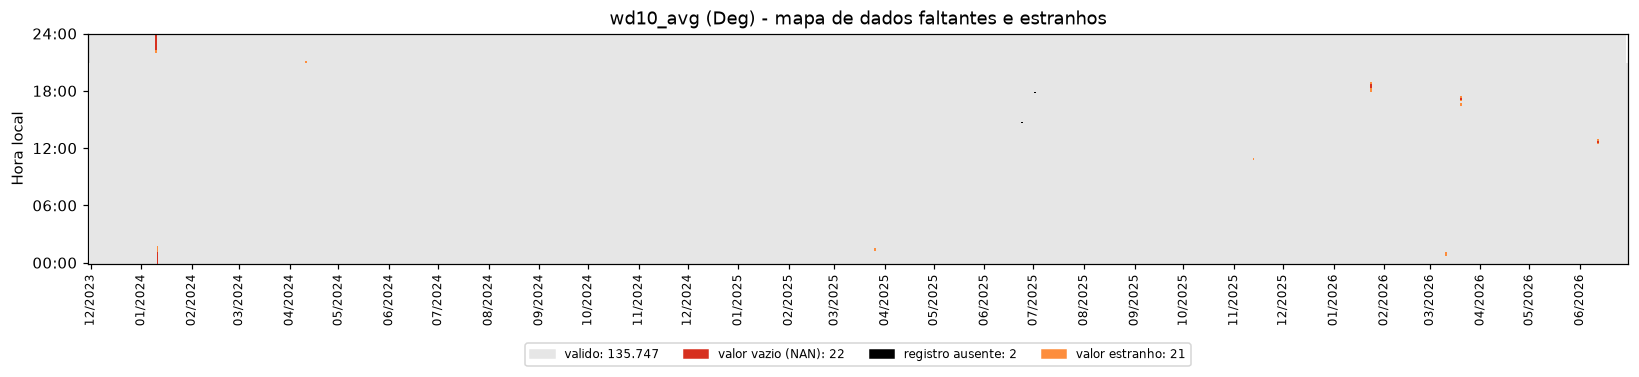

In [14]:
VARIAVEIS_MAPA = ["tp_sfc", "humid", "press", "rain", "ws10_avg", "wd10_avg"]

CORES_MAPA = ["#e6e6e6", "#d7301f", "#000000", "#fd8d3c"]
NOMES_MAPA = ["valido", "valor vazio (NAN)", "registro ausente", "valor estranho"]

local = dados.index + FUSO_LOCAL
dia_local = local.normalize()
dias_mapa = pd.date_range(dia_local.min(), dia_local.max(), freq="D")
coluna = ((dia_local - dias_mapa[0]).days).to_numpy()
linha = ((local.hour * 60 + local.minute) // 10).to_numpy()


def mapa_variavel(variavel):
    categoria = np.zeros(len(dados), dtype=int)
    categoria[faltante[variavel].to_numpy()] = 1
    categoria[registro_ausente.to_numpy()] = 2
    categoria[estranho[variavel].to_numpy()] = 3
    imagem = np.full((144, len(dias_mapa)), np.nan)
    imagem[linha, coluna] = categoria

    fig, eixo = plt.subplots(figsize=(15, 3.8))
    eixo.imshow(imagem, aspect="auto", interpolation="nearest", origin="lower",
                cmap=ListedColormap(CORES_MAPA), vmin=-0.5, vmax=3.5)
    eixo.set_yticks(range(0, 145, 36), ["00:00", "06:00", "12:00", "18:00", "24:00"])
    eixo.set_ylabel("Hora local")
    meses = [i for i, dia in enumerate(dias_mapa) if dia.day == 1]
    eixo.set_xticks(meses, [dias_mapa[i].strftime("%m/%Y") for i in meses], rotation=90, fontsize=8)
    eixo.grid(False)
    contagens = [(categoria == k).sum() for k in range(4)]
    eixo.legend(
        handles=[Patch(color=c, label=f"{n}: {q:,}".replace(",", ".")) for c, n, q in zip(CORES_MAPA, NOMES_MAPA, contagens)],
        loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4, fontsize=8,
    )
    eixo.set_title(f"{variavel} ({UNIDADES[variavel]}) - mapa de dados faltantes e estranhos")
    fig.tight_layout()
    plt.show()


for variavel in VARIAVEIS_MAPA:
    mapa_variavel(variavel)

## 6. Séries completas e zoom nos episódios

### 6.1 Série completa de cada variável

Linha azul: valores válidos. Pontos laranja: valores estranhos. Faixas vermelhas: falhas de mais de
1 h. Os códigos de falha (999) ficam de fora do gráfico para não achatar a escala.

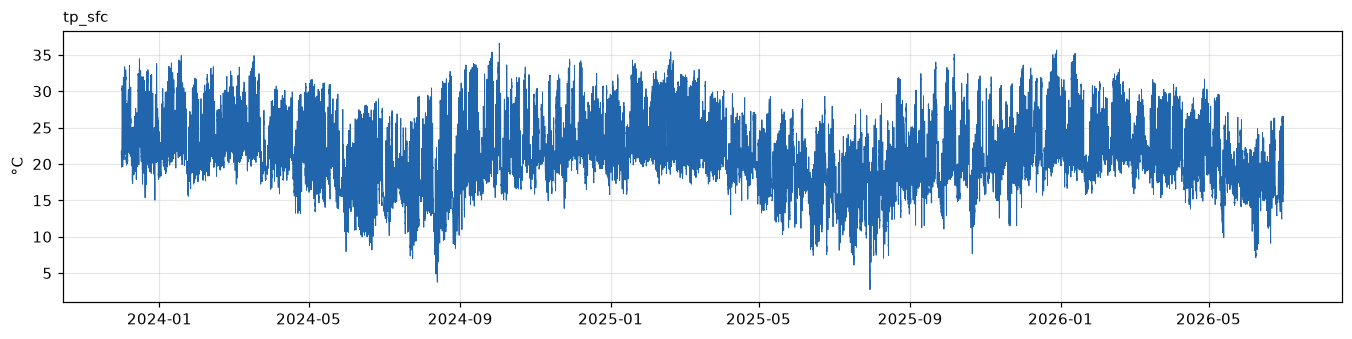

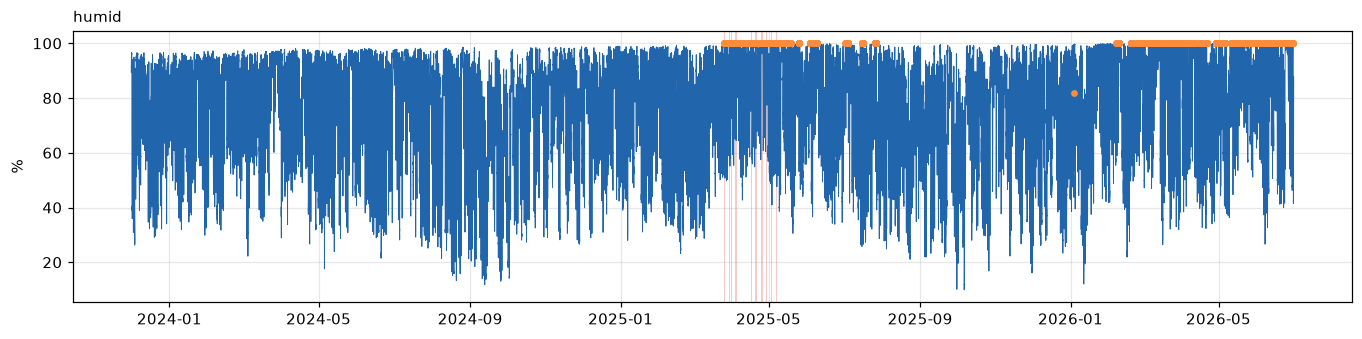

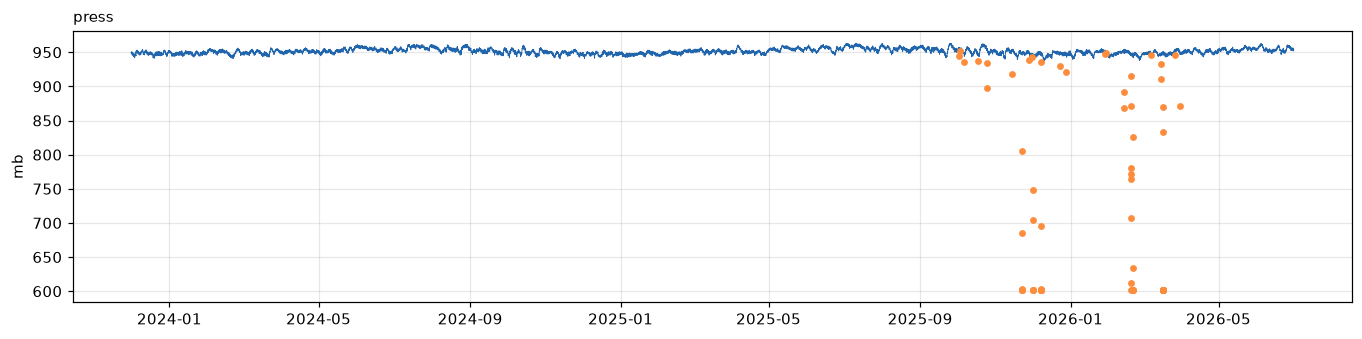

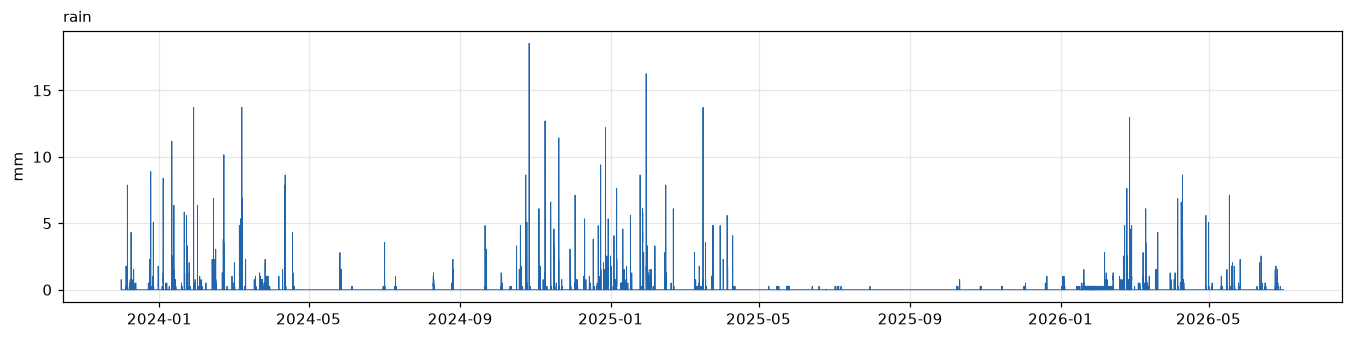

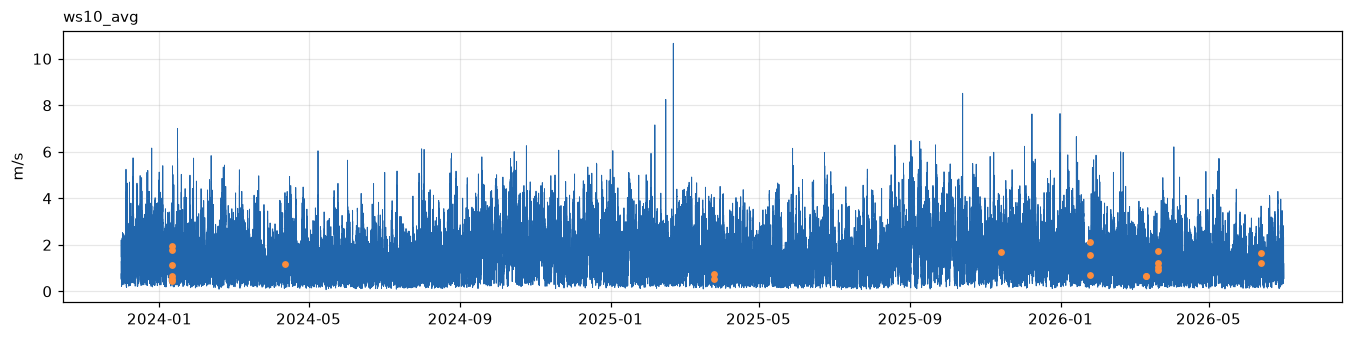

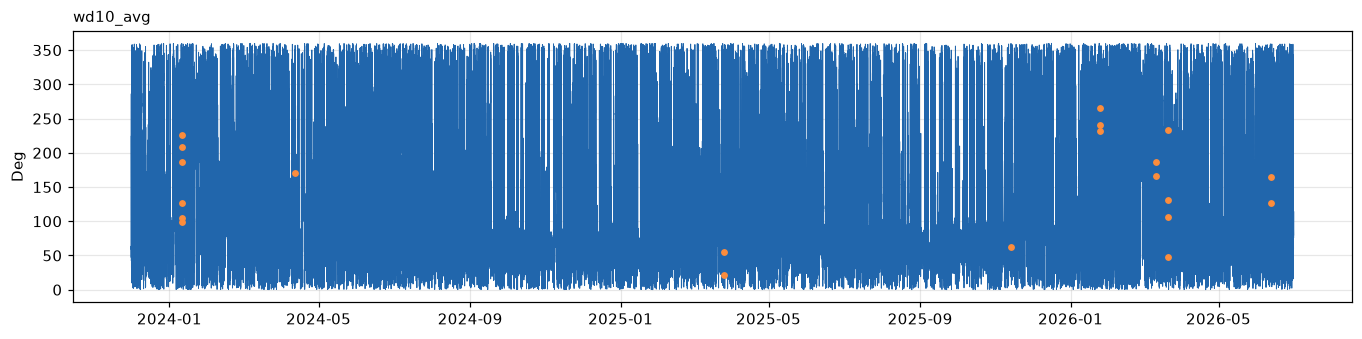

In [15]:
def plotar_serie(variavel, inicio=None, fim=None, eixo=None):
    trecho = slice(inicio, fim)
    serie = medidas[variavel].loc[trecho]
    marcado = estranho[variavel].loc[trecho] & (serie.abs() < LIMITE_CODIGO)
    if eixo is None:
        _, eixo = plt.subplots(figsize=(15, 3.2))
    eixo.plot(serie.where(~estranho[variavel].loc[trecho]), color="#2166ac", lw=0.6)
    eixo.scatter(serie.index[marcado], serie[marcado], color="#fd8d3c", s=12, zorder=3, label="estranho")
    tabela = falhas.query("variavel == @variavel")
    tabela = tabela[tabela["registros"] > 6]
    for ini, fim_falha in zip(tabela["inicio_utc"], tabela["fim_utc"]):
        if (inicio is None or fim_falha >= pd.Timestamp(inicio)) and (fim is None or ini <= pd.Timestamp(fim)):
            eixo.axvspan(ini - PASSO, fim_falha, color="#d7301f", alpha=0.25, lw=0)
    eixo.set_ylabel(UNIDADES[variavel])
    eixo.set_title(variavel, loc="left", fontsize=10)
    return eixo


for variavel in VARIAVEIS_MAPA:
    eixo = plotar_serie(variavel)
    plt.show()

### 6.2 Zoom nos episódios

Para cada item de `ZOOM`, mostra os maiores episódios de uma variável (estranhos ou faltantes), com 6 h
antes e depois. Para ver um trecho qualquer, use, por exemplo:
`plotar_serie("press", "2025-11-22 10:00", "2025-11-22 20:00"); plt.show()`.

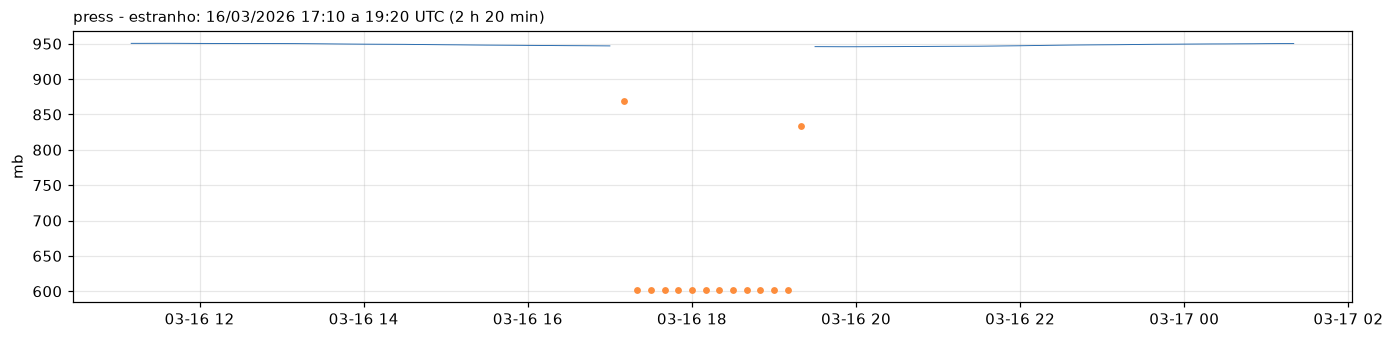

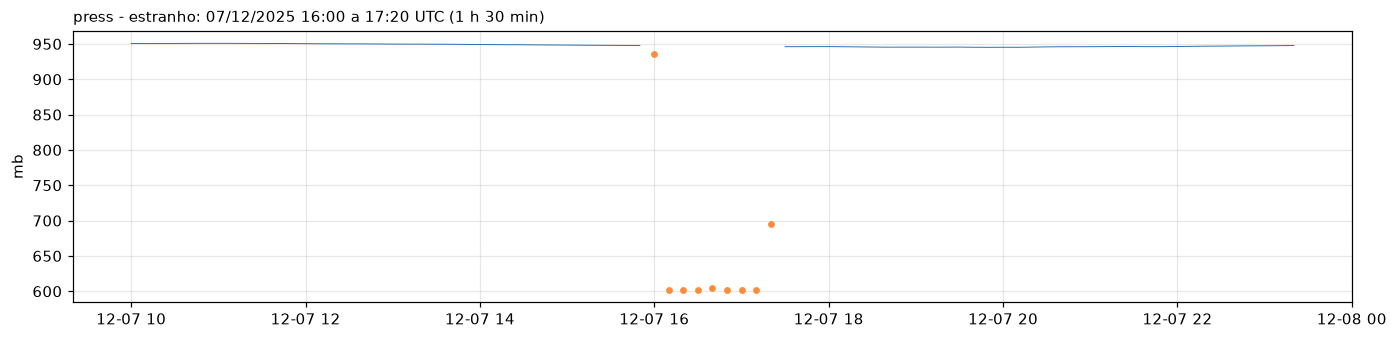

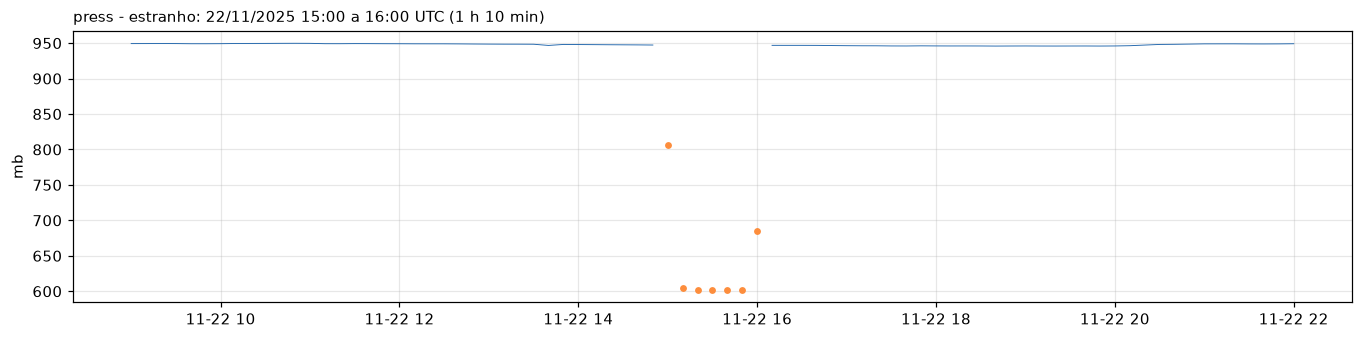

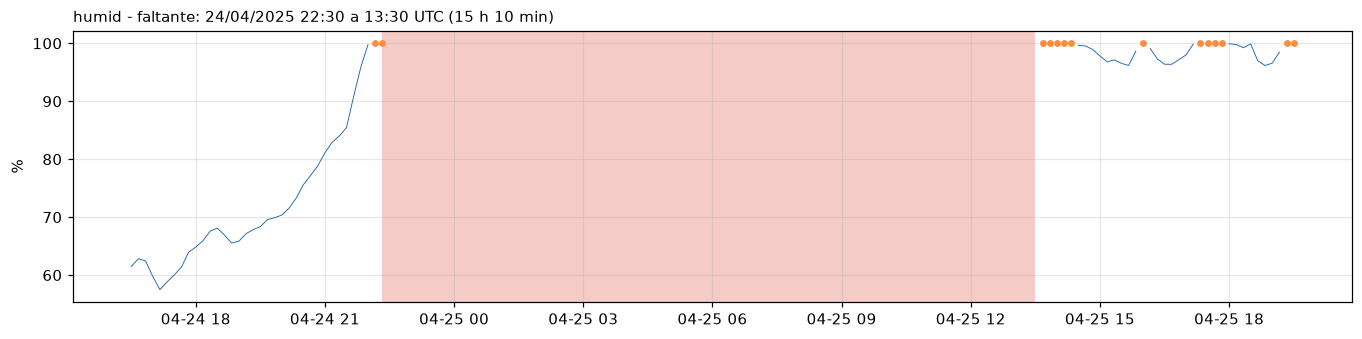

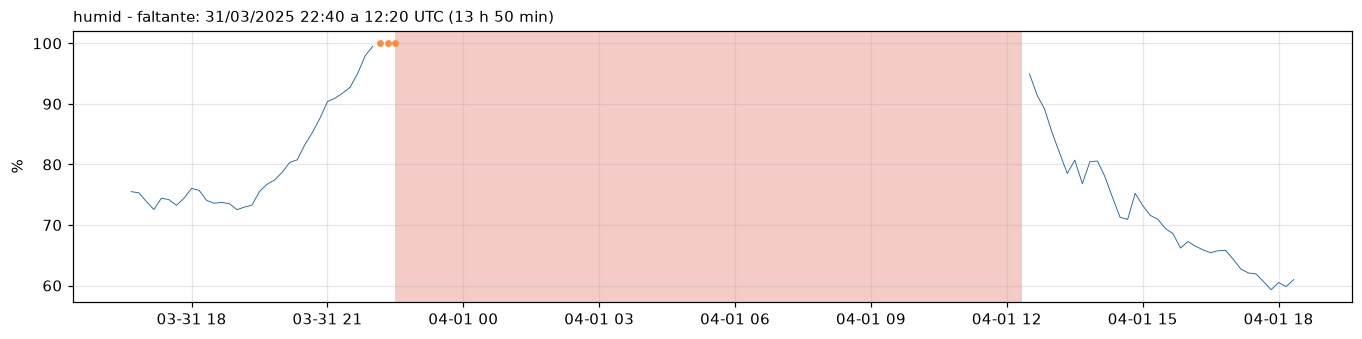

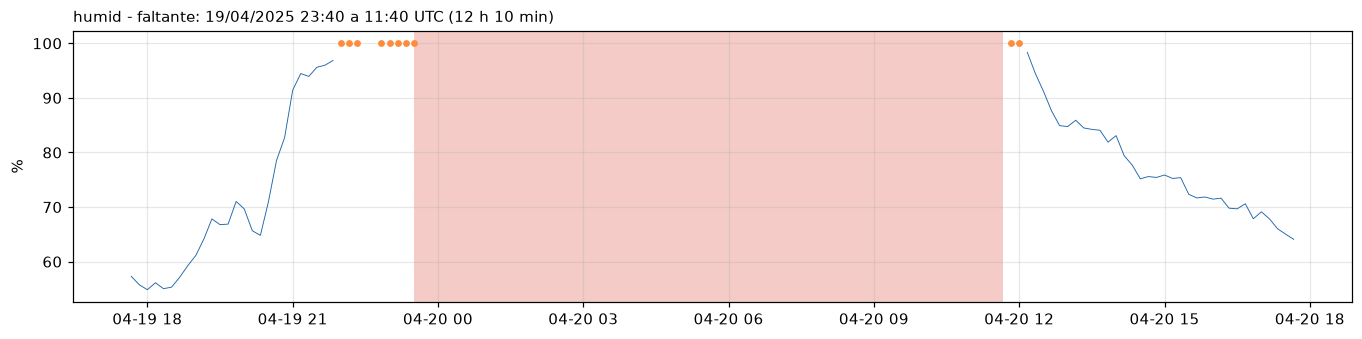

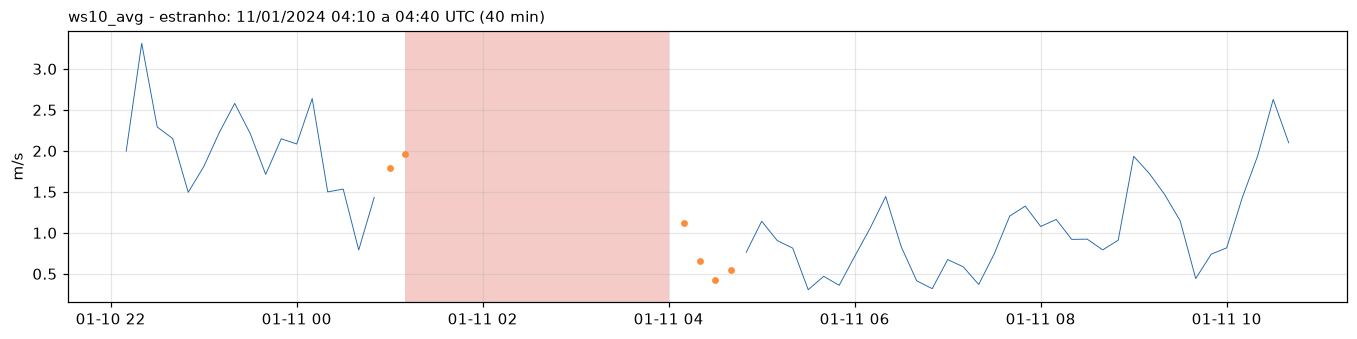

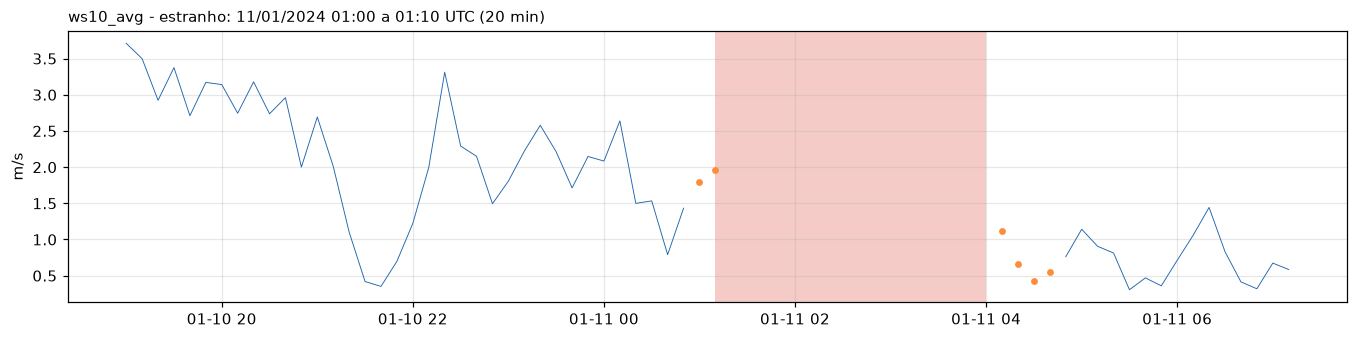

In [16]:
ZOOM = [("press", "estranho", 3), ("humid", "faltante", 3), ("ws10_avg", "estranho", 2)]
MARGEM = pd.Timedelta(hours=6)

for variavel, tipo, quantidade in ZOOM:
    fonte = episodios_estranhos if tipo == "estranho" else falhas
    if fonte.empty:
        continue
    maiores = fonte.query("variavel == @variavel").nlargest(quantidade, "registros")
    for _, episodio in maiores.iterrows():
        eixo = plotar_serie(variavel, episodio["inicio_utc"] - MARGEM, episodio["fim_utc"] + MARGEM)
        eixo.set_title(
            f"{variavel} - {tipo}: {episodio['inicio_utc']:%d/%m/%Y %H:%M} a {episodio['fim_utc']:%H:%M} UTC "
            f"({episodio['duracao']})", loc="left", fontsize=10,
        )
        plt.show()

## 7. Exportação

Com `SALVAR_TABELAS = True`, as tabelas vão para `2026/sonda_unificada/MD/diagnostico/`:

- `resumo_faltantes.csv`: quanto falta em cada variável;
- `intervalos_faltantes.csv`: cada falha, com início, fim e duração;
- `registros_ausentes.csv`: horários sem nenhum registro;
- `valores_estranhos_contagem.csv` e `valores_estranhos_episodios.csv`: o resultado das regras da seção 4.

In [17]:
if SALVAR_TABELAS:
    PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
    resumo_faltantes.to_csv(PASTA_SAIDA / "resumo_faltantes.csv", index=False)
    falhas.to_csv(PASTA_SAIDA / "intervalos_faltantes.csv", index=False)
    tabela_ausentes.to_csv(PASTA_SAIDA / "registros_ausentes.csv", index=False)
    contagem.to_csv(PASTA_SAIDA / "valores_estranhos_contagem.csv")
    episodios_estranhos.to_csv(PASTA_SAIDA / "valores_estranhos_episodios.csv", index=False)
    for arquivo in sorted(PASTA_SAIDA.iterdir()):
        print(arquivo.name)

intervalos_faltantes.csv
registros_ausentes.csv
resumo_faltantes.csv
valores_estranhos_contagem.csv
valores_estranhos_episodios.csv
